# Inference Notebook

In [1]:
from pathlib import Path
REPO = Path.cwd()
while not (REPO / "Author_Code").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
MODEL_RUN = REPO / "Results" / "Training Runs" / "Stead Runs" / "Branch_Encoder_Decoder_LSTM_warmup"
MODEL_ID = "ours_LSTM_seed99"
DATA_DIRS = [REPO.parent / "Data" / "Stead Data", REPO.parent / "Data", REPO / "Data"]
TRAIN_NAME = "training_datasets_all_snr_40_unshuffled.hdf5"
POHA_NAME = "training_datasets_STEAD_plus_POHA_snr_40_unshuffled.hdf5"
STEAD_NAME = "training_datasets_STEAD_waveform_snr_40.hdf5"
CACHE = REPO / "Data" / "samples" / "stead_examples_LSTM_seed99.npz"
OUT_DIR = REPO / "Results" / "Inference"
REBUILD = False
SAMPLE = 0
EXAMPLE_SEED = 7
EV_CLIP = -1.0
FAIL_FRACTION = 0.02
N_TOTAL = 187000

In [2]:
import sys, json, time
import numpy as np

AUTHOR_CODE = str(REPO / "Author_Code")
if AUTHOR_CODE not in sys.path:
    sys.path.insert(0, AUTHOR_CODE)

import torch
import matplotlib.pyplot as plt

def find_file(name, roots):
    for root in roots:
        if root.is_dir():
            hits = sorted(root.rglob(name))
            if hits:
                return hits[0]
    return None

SAVED = find_file("example_waveforms_%s.npz" % MODEL_ID, [REPO / "Results"])
print("repo           ", REPO)
print("torch          ", torch.__version__)
print("model run      ", MODEL_RUN, "(found)" if MODEL_RUN.is_dir() else "(MISSING)")
print("cache          ", "present" if CACHE.exists() else "not yet built")
print("notebook 03 npz", SAVED or "not found")
for name in (TRAIN_NAME, POHA_NAME, STEAD_NAME):
    print("%-15s %s" % (name.split("_snr")[0].replace("training_datasets_", ""), find_file(name, DATA_DIRS) or "not found"))

repo            c:\Users\HP\Desktop\DAT-102\Code
torch           2.10.0+cpu
model run       c:\Users\HP\Desktop\DAT-102\Code\Results\Training Runs\Stead Runs\Branch_Encoder_Decoder_LSTM_warmup (found)
cache           present
notebook 03 npz not found
all             c:\Users\HP\Desktop\DAT-102\Data\Stead Data\training_datasets_all_snr_40_unshuffled.hdf5
STEAD_plus_POHA c:\Users\HP\Desktop\DAT-102\Data\Stead Data\training_datasets_STEAD_plus_POHA_snr_40_unshuffled.hdf5
STEAD_waveform  c:\Users\HP\Desktop\DAT-102\Data\Stead Data\training_datasets_STEAD_waveform_snr_40.hdf5


## Load the model

In [3]:
found = sorted(MODEL_RUN.glob("*_Model.pth"))
if not found:
    raise FileNotFoundError("No *_Model.pth in\n    %s\nCheck MODEL_RUN in the configuration cell." % MODEL_RUN)
MODEL_PATH = found[0]

# weights_only=False: the file holds a whole pickled model, not a state dict.
model = torch.load(str(MODEL_PATH), map_location="cpu", weights_only=False).double().eval()

print("file        ", MODEL_PATH.name)
print("parameters  ", format(sum(p.numel() for p in model.parameters()), ","))
info_path = MODEL_RUN / "run_info.json"
if info_path.exists():
    info = json.loads(info_path.read_text())
    print("bottleneck  ", info.get("bottleneck"))
    print("training    ", "%s epochs, seed %s" % (info.get("epochs"), info.get("torch_seed")))
    print("final loss  ", "train %.5f, validation %.5f"
          % (info.get("final_train_loss", float("nan")), info.get("final_val_loss", float("nan"))))
    if info.get("bottleneck") != "LSTM":
        raise ValueError("MODEL_RUN is not an LSTM run.")

file         Branch_Encoder_Decoder_LSTM_Model.pth
parameters   178,442
bottleneck   LSTM
training     100 epochs, seed 99
final loss   train 0.04159, validation 0.04447


## Helper functions

In [4]:
def predict(x, batch=256):
    """x: (n, 3, 600) -> (earthquake, noise), both (n, 3, 600)."""
    eq, noise = np.empty_like(x), np.empty_like(x)
    with torch.no_grad():
        for i in range(0, len(x), batch):
            a, b = model(torch.from_numpy(np.ascontiguousarray(x[i:i + batch])))
            eq[i:i + batch], noise[i:i + batch] = a.numpy(), b.numpy()
    return eq, noise


def ev_score(y, p):
    """Explained variance per trace and component (time is the last axis), as in notebook 03."""
    d = y - p
    num = d.var(axis=-1)
    den = y.var(axis=-1)
    out = np.ones_like(num)
    ok = (num != 0) & (den != 0)
    out[ok] = 1 - num[ok] / den[ok]
    out[(num != 0) & (den == 0)] = 0.0
    return out

## Get the nine examples

* **good**: random picks from the top 10 % by EV
* **average**: random picks from the 200 traces closest to the median EV
* **failure**: random picks from the worst 2 %


In [5]:
def read_rows(path, rows, chunk=5000):
    """Yield (positions, X, Y) for the wanted file rows, reading the file in blocks. X, Y: (n, 3, 600)."""
    import h5py
    order = np.argsort(rows)
    ordered = rows[order]
    with h5py.File(path, "r") as f:
        for lo in range(0, f["X_train"].shape[0], chunk):
            a, b = np.searchsorted(ordered, [lo, lo + chunk])
            if b > a:
                sel = ordered[a:b] - lo
                x = f["X_train"][lo:lo + chunk][sel]
                y = f["Y_train"][lo:lo + chunk][sel]
                yield (order[a:b], np.moveaxis(x, 1, -1).astype(np.float64),
                       np.moveaxis(y, 1, -1).astype(np.float64))

def row_metadata(train_path, rows):
    """SNR and earthquake energy fraction of the given rows, or None if the files are not there."""
    import h5py
    poha, stead = find_file(POHA_NAME, DATA_DIRS), find_file(STEAD_NAME, DATA_DIRS)
    if poha is None or stead is None:
        return None
    with h5py.File(train_path, "r") as f:
        src = f["source_index"][:][rows]
        n_poha = int(f.attrs["n_poha"])
    out = {k: np.full(len(rows), np.nan) for k in ("snr", "quake_energy_frac")}
    is_poha = src < n_poha
    for path, mask, offset in ((poha, is_poha, 0), (stead, ~is_poha, n_poha)):
        with h5py.File(path, "r") as f:
            for k in out:
                out[k][mask] = f[k][:][src[mask] - offset]
    return out

def build_examples():
    import h5py
    from sklearn.model_selection import train_test_split

    train_path = find_file(TRAIN_NAME, DATA_DIRS)
    if train_path is None:
        raise FileNotFoundError(
            "No saved examples, and the training file\n    %s\nwas not found under:\n    %s\n\n"
            "Do one of these:\n"
            "  1. copy example_waveforms_%s.npz (Part C of notebook 03) anywhere under Results/\n"
            "  2. put the training file in one of the folders above, or add its folder to DATA_DIRS"
            % (TRAIN_NAME, "\n    ".join(map(str, DATA_DIRS)), MODEL_ID))

    with h5py.File(train_path, "r") as f:
        n = f["X_train"].shape[0]
    if n != N_TOTAL:
        raise ValueError("%s has %d rows, expected %d, so the test split would not match." % (train_path, n, N_TOTAL))
    _, rest = train_test_split(np.arange(n), train_size=0.6, random_state=13)
    _, test_rows = train_test_split(rest, test_size=0.5, random_state=20)

    scores = find_file("per_sample_%s.csv.gz" % MODEL_ID, [REPO / "Results"])
    if scores is not None:
        import pandas as pd
        df = pd.read_csv(scores).sort_values("row")
        if not np.array_equal(df.file_row.to_numpy(), test_rows):
            raise ValueError("%s does not match the test split." % scores)
        v = df.ev_eq_mean_clipped.to_numpy()
        raw = df[["ev_eq_c0", "ev_eq_c1", "ev_eq_c2"]].to_numpy().mean(1)
        snr, frac = df.snr.to_numpy(), df.quake_energy_frac.to_numpy()
        print("scores reused from", scores.name)
    else:
        ev = np.empty((len(test_rows), 3))
        t0, done = time.time(), 0
        for pos, x, y in read_rows(train_path, test_rows):
            ev[pos] = ev_score(y, predict(x)[0])
            done += len(pos)
            print("\rscored %d / %d  (%.0f s)" % (done, len(test_rows), time.time() - t0), end="")
        print()
        v, raw = np.clip(ev, EV_CLIP, 1).mean(1), ev.mean(1)
        meta = row_metadata(train_path, test_rows)
        if meta is None:
            print("WARNING: the POHA / STEAD mixture files were not found. SNR is shown as n/a, the 1 % "
                  "energy filter is off, and the picks will differ from notebook 03.")
            snr, frac = np.full(len(v), np.nan), np.ones(len(v))
        else:
            snr, frac = meta["snr"], meta["quake_energy_frac"]

    rng = np.random.default_rng(EXAMPLE_SEED)
    sig = frac >= 0.01
    order = np.lexsort((raw, v))
    nfail = max(1, int(FAIL_FRACTION * len(v)))
    good = np.where(sig & (v >= np.quantile(v[sig], 0.9)))[0]
    median = np.median(v[sig])
    average = np.where(sig)[0][np.argsort(np.abs(v[sig] - median))[:200]]
    picks = {"good": rng.choice(good, 3, replace=False),
             "average": rng.choice(average, 3, replace=False),
             "failure": rng.choice(order[:nfail], 3, replace=False)}
    idx = np.concatenate(list(picks.values()))

    X, Y = np.empty((len(idx), 3, 600)), np.empty((len(idx), 3, 600))
    for pos, x, y in read_rows(train_path, test_rows[idx]):
        X[pos], Y[pos] = x, y
    return dict(X=X, Y=Y, kind=np.repeat(list(picks), 3), test_row=idx, snr=snr[idx])


source = CACHE if CACHE.exists() else SAVED
if source is not None and not REBUILD:
    with np.load(source) as z:
        ex = {k: z[k] for k in ("X", "Y", "kind", "test_row", "snr")}
    print("examples loaded from", source)
else:
    ex = build_examples()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(CACHE, **ex)
    print("examples saved to", CACHE)

X, Y = ex["X"], ex["Y"]
print("mixtures", X.shape, "| targets", Y.shape)

examples loaded from c:\Users\HP\Desktop\DAT-102\Code\Data\samples\stead_examples_LSTM_seed99.npz
mixtures (9, 3, 600) | targets (9, 3, 600)


## Grid Plots

In [6]:
t0 = time.time()
pred_eq, pred_noise = predict(X)
print("forward pass on %d traces: %.0f ms" % (len(X), 1e3 * (time.time() - t0)))

ev_eq = ev_score(Y, pred_eq)                       # (n, 3)
ev_noise = ev_score(X - Y, pred_noise)
ev_label = np.clip(ev_eq, EV_CLIP, 1).mean(1)      # the EV written beside each row

print("\n #  kind      test row      SNR   EV earthquake   EV noise   (clipped at -1, mean of E, N, Z)")
for i in range(len(X)):
    snr = "%7.2f" % ex["snr"][i] if np.isfinite(ex["snr"][i]) else "    n/a"
    print("%2d  %-8s  %8d  %s  %14.4f  %9.4f"
          % (i, ex["kind"][i], ex["test_row"][i], snr, ev_label[i], np.clip(ev_noise[i], EV_CLIP, 1).mean()))

forward pass on 9 traces: 73 ms

 #  kind      test row      SNR   EV earthquake   EV noise   (clipped at -1, mean of E, N, Z)
 0  good         35482    86.67          0.9987    -0.0513
 1  good         23472    63.07          0.9984    -0.3276
 2  good         25544    95.11          0.9989    -0.0311
 3  average       4886     0.28          0.9826     0.9986
 4  average      37235     0.48          0.9828     0.9967
 5  average       5779     0.74          0.9832     0.9925
 6  failure      35608     1.31         -1.0000     0.9994
 7  failure       8062     0.18         -1.0000     0.9986
 8  failure      24627     0.88         -1.0000     0.9994


saved to c:\Users\HP\Desktop\DAT-102\Code\Results\Inference


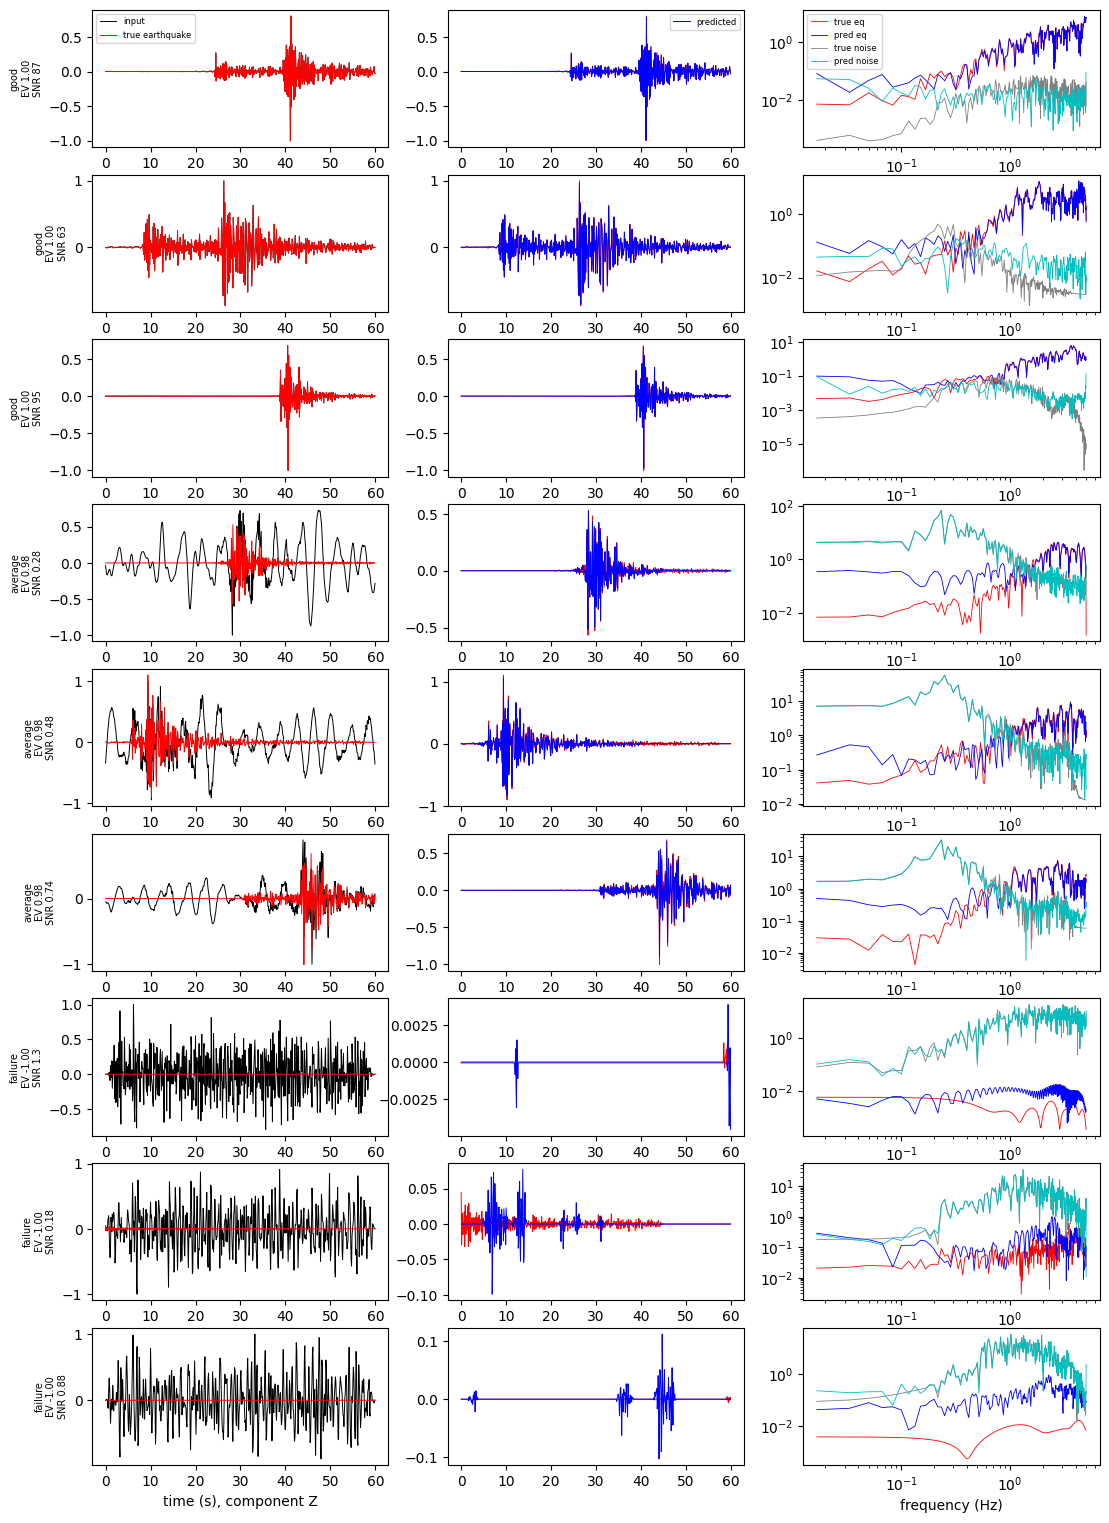

In [7]:
def example_grid(component=2):
    n = len(X)
    t = np.arange(600) / 10
    f = np.fft.rfftfreq(600, 0.1)[1:]
    c = component
    fig, ax = plt.subplots(n, 3, figsize=(13, 2.1 * n), squeeze=False)
    for r in range(n):
        sc = np.max(np.abs(X[r, c])) + 1e-12       # every trace is scaled by the input peak
        ax[r, 0].plot(t, X[r, c] / sc, "k", lw=0.7, label="input")
        ax[r, 0].plot(t, Y[r, c] / sc, "r", lw=0.7, label="true earthquake")
        ax[r, 1].plot(t, Y[r, c] / sc, "r", lw=0.7)
        ax[r, 1].plot(t, pred_eq[r, c] / sc, "b", lw=0.7, label="predicted")
        for a, lab, col in ((Y[r, c], "true eq", "r"), (pred_eq[r, c], "pred eq", "b"),
                            (X[r, c] - Y[r, c], "true noise", "gray"), (pred_noise[r, c], "pred noise", "c")):
            ax[r, 2].loglog(f, np.abs(np.fft.rfft(a / sc))[1:], col, lw=0.6, label=lab)
        snr = "%.2g" % ex["snr"][r] if np.isfinite(ex["snr"][r]) else "n/a"
        ax[r, 0].set_ylabel("%s\nEV %.2f\nSNR %s" % (ex["kind"][r], ev_label[r], snr), fontsize=7)
    for j in range(3):
        ax[0, j].legend(fontsize=6)
    name = "ENZ"[c]
    ax[-1, 0].set_xlabel("time (s), component %s" % name)
    ax[-1, 2].set_xlabel("frequency (Hz)")
    return fig


fig = example_grid(component=2)          # 0 = E, 1 = N, 2 = Z
OUT_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / ("fig_examples_%s.%s" % (MODEL_ID, ext)), bbox_inches="tight", dpi=200)
print("saved to", OUT_DIR)
plt.show()